In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from glob import glob
import subprocess
import tempfile
from os.path import dirname

/gpfs/home/qcf21tku/.conda/envs/bio/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.25.2
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [2]:
!ls /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/*/vamb_multi/umap_vamb.tsv

/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E01_1/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E01_2/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E02_1/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E02_2/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E03_1/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E04_1/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E04_2/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E04_3/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E07_1/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E07_2/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E09_1/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E11_

In [3]:
sample_title = {
    "E06_1":"MOSAiC Water June",
    "I06_1":"MOSAiC Ice June",
    "E07_1":"MOSAiC Water July",
    "I07_1":"MOSAiC Ice July",
}

In [10]:
sample = "E04_2"

binning_dir = f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir"
taxo_dir = f"/gpfs/data/mock_lab/will/mosaic_tmp/taxo_tmpdir"

In [11]:
df_umap_coords = pd.read_csv(f"{binning_dir}/{sample}/vamb_multi/umap_vamb.tsv", sep = '\t')
df_umap_coords['sample'] = df_umap_coords.contig_id.apply(lambda x: x.split('_')[0])
df_umap_coords.head()

,contig_id,umap_0,umap_1,sample
0,3300060028_Ga0586929_0000077,9.024560,5.917784,3300060028
1,3300060028_Ga0586929_0000376,3.471160,10.947493,3300060028
2,3300060028_Ga0586929_0000531,8.635929,11.088510,3300060028
3,3300060028_Ga0586929_0000623,9.871797,12.899798,3300060028
4,3300060028_Ga0586929_0000632,7.477658,11.938110,3300060028


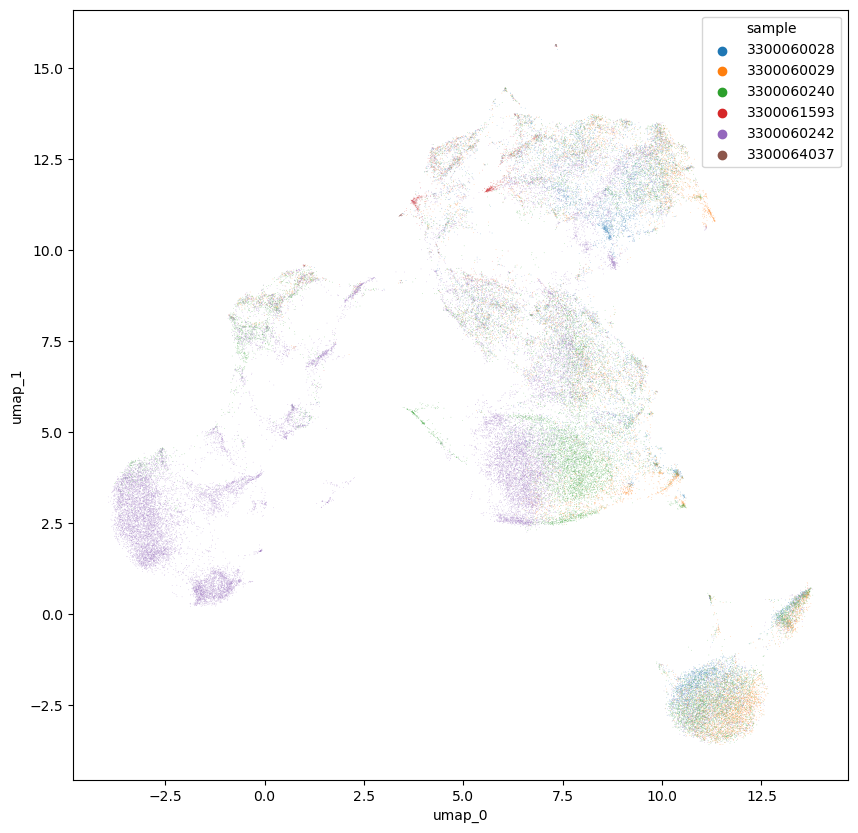

In [12]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df_umap_coords, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    hue = 'sample',
    alpha = 0.5
)

In [13]:
single_samples = list(set(df_umap_coords['sample']))

def make_taxo_df(sample_id):
    df = pd.read_csv(f"{taxo_dir}/{sample_id}/{sample_id}.faa.mms2lca", sep = '\t')
    df['sample'] = sample_id
    df['contig_id'] = df['sample'] + '_' + df['contig_id']
    return df

df_taxo = pd.concat(
    make_taxo_df(s) for s in single_samples
)

df = pd.merge(
    df_umap_coords, 
    df_taxo, 
    on = ['contig_id', 'sample'],
    how = 'left'
).fillna("Unknown")

In [14]:
#top_10 = list(df.groupby('name').count().sort_values('contig_id', ascending = False).head(10).index)

favourite_groups = [
    "Bacillariophyta", 
    "Nucleocytoviricota", 
    "Mamiellophyceae",
    "Dinophyceae",
    "Metazoa",
    "Cryptophyceae",
    "Haptophyta", 
    "Chlorophyta", 
    "Euglenozoa",
    "Ciliophora",
    "Labyrinthulomycetes", 
    "Chrysophyceae", 
    "Choanoflagellata", 
    "Microbotryomycetes", 
    "Amoebozoa", 
    "Ochrophyta", 
    "Chytridiomycota"
]


def simplify_name(row):
    if row.superkingdom in ["Bacteria", "Archaea"]:
        return "Prokaryota"
    
    if row.superkingdom == "Unknown":
        if row['name'] == "Viruses":
            return "Viruses"
        return "Unknown"
    
    for x in favourite_groups:
        if x in row.lineage:
            return x

    if row.superkingdom == "Virus":
        return "Viruses"
    
    return row.superkingdom
    
    
df['name_simple'] = df.apply(simplify_name, axis = 1)

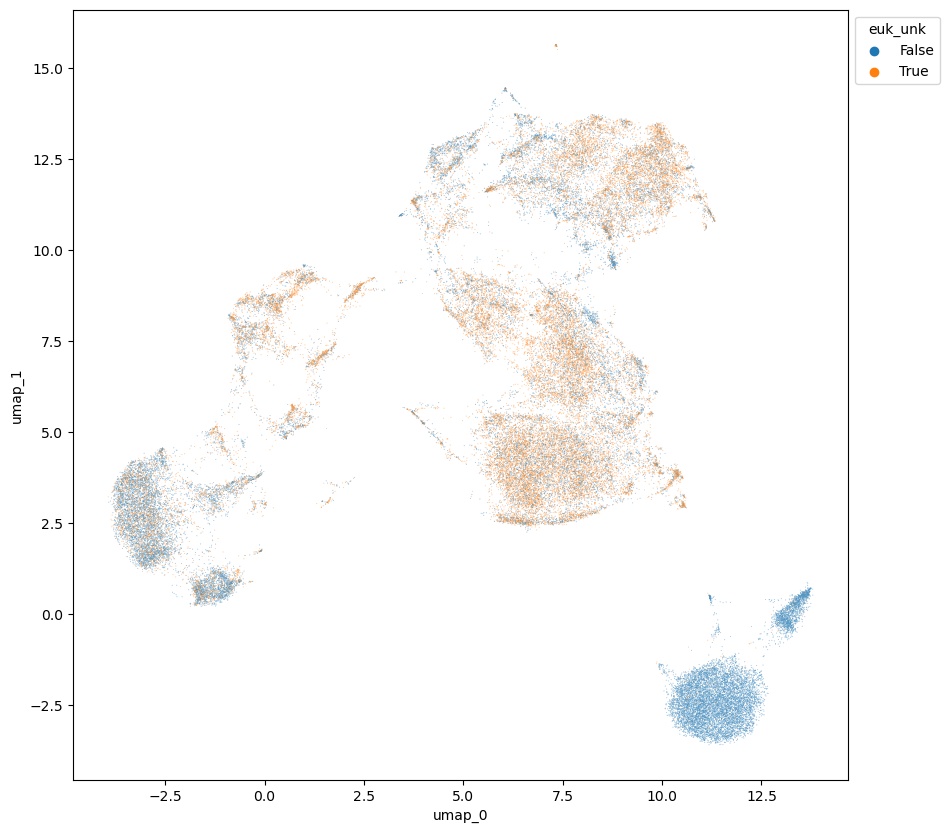

In [15]:
df['euk_unk'] = df.name_simple.isin(["Unknown", "Eukaryota"])

plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df,
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.5, 
    hue = 'euk_unk',
    alpha = 0.5
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

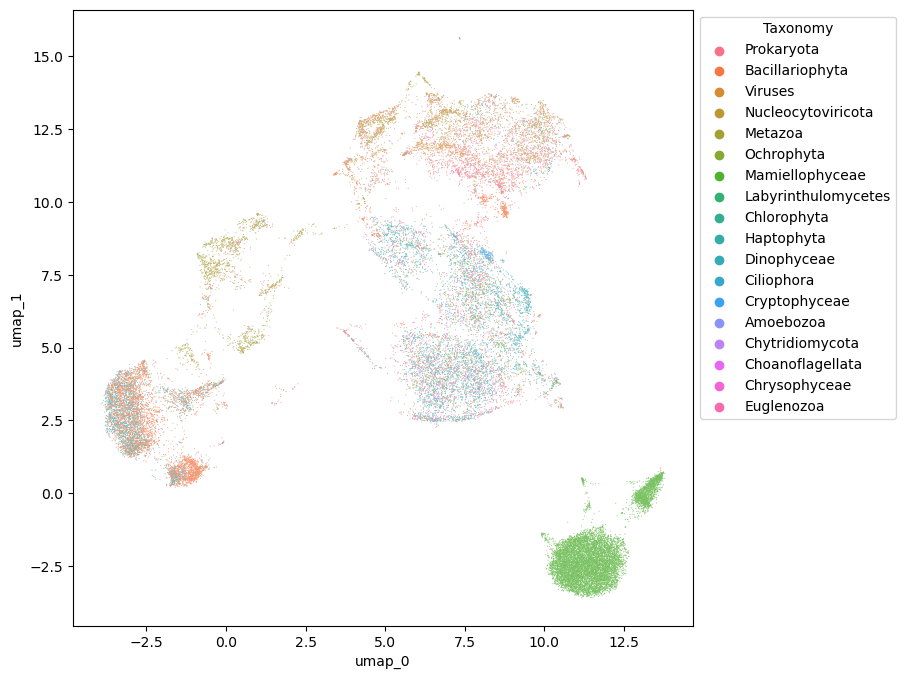

In [17]:
plt.figure(figsize = (8, 8))
ax = sns.scatterplot(
    data = df[~df.name_simple.isin(["Unknown", "Eukaryota"])],
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.5, 
    hue = 'name_simple',
    alpha = 0.85
)
plt.title(sample_title.get(sample))
plt.legend(title='Taxonomy')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

#plt.savefig(f"/gpfs/home/qcf21tku/svgs/{sample}_valence_taxplot.svg")

In [18]:
# Below here is done on a per-sample basis... Don't rerun!


In [19]:
df_bin = pd.read_csv(
    f"/gpfs/home/qcf21tku/scratch/refine_chap/{sample}_bins.tsv", 
    sep = '\t', 
    header = None, 
    names = ['bin_id', 'contig_id']
)

df2 = pd.merge(df, df_bin, on = 'contig_id', how = 'left').fillna('unbinned')
df2['binned'] = df2.bin_id.apply(lambda x: 'unbinned' if x == 'unbinned' else 'binned')

FileNotFoundError: [Errno 2] No such file or directory: '/gpfs/home/qcf21tku/scratch/refine_chap/E04_2_bins.tsv'

In [ ]:
contig_lengths = np.load(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample}/vamb_multi/lengths.npz"
)['arr_0']

contignames = pd.read_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample}/vamb_multi/contignames", 
    header = None, 
    names = ['contig_id']
)

In [ ]:
contignames.shape

In [ ]:
[x for x in contig_lengths if x < 2000]

In [ ]:
plt.figure(figsize = (8, 8))
ax = sns.scatterplot(
    data = df2[~df2.name_simple.isin(["Unknown", "Eukaryota"])],
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.5, 
    hue = 'binned',
    alpha = 0.85
)
plt.title(sample_title.get(sample))
plt.legend(title='Binning Status')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))


In [24]:
df[(df.umap_0 < 0) & (df.umap_1 < 5)].lineage.value_counts().head(25)

Eukaryota;Sar                                                                                                                                                                                         1767
Eukaryota;Sar;Alveolata;Dinophyceae;Peridiniales;Kryptoperidiniaceae;Kryptoperidinium;Kryptoperidinium foliaceum                                                                                      1497
Unknown                                                                                                                                                                                               1431
Eukaryota;Sar;Stramenopiles;Ochrophyta;Bacillariophyta                                                                                                                                                1175
Eukaryota;Sar;Stramenopiles;Ochrophyta;Bacillariophyta;Coscinodiscophyceae;Chaetocerotophycidae;Chaetocerotales;Attheyaceae;Attheya;Attheya septentrionalis                                 

In [ ]:
df['target'] = ((df.umap_1 > 10) & (df.umap_1 < 15) & (df.umap_0 > 3.5) & (df.umap_0 < 6.5))

plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df,
    x = 'umap_0', 
    y = 'umap_1', 
    s = 2.5, 
    hue = 'target', palette = ['lightgrey', 'green'],
    alpha = 0.85
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [ ]:
! cat {binning_dir}/{sample}/all_bins_multi_auto_eukcc/eukcc.csv

! wc -m {binning_dir}/{sample}/all_bins_multi_auto/*.fna | sort -nr -k 1

In [ ]:
! wc -m {binning_dir}/{sample}/all_bins_multi_manual/*.fna

In [ ]:
df[df.target].groupby(
    'name_simple'
)[['contig_id']].count().sort_values('contig_id', ascending = False).head(10)

In [ ]:
def extract_contigs(df, path_to_contigs, output_path, contig_column = 'contig_id'):
    """
    Extract contigs based on a 'contig_id' column in a DataFrame.

    Args:
        df (pd.DataFrame): The DataFrame containing contig IDs.
        contig_column (str): The name of the column with contig IDs.
        path_to_contigs (str): Path to the file containing all contigs (FASTA).
        output_path (str): Path to save the extracted contigs (FASTA).
    """
    # Ensure the contig_column exists
    if contig_column not in df.columns:
        raise ValueError(f"Column '{contig_column}' not found in DataFrame.")

    # Extract unique contig IDs
    contig_ids = df[contig_column].drop_duplicates().tolist()

    # Use a temporary file to hold contig IDs
    with tempfile.NamedTemporaryFile(mode="w", delete=True) as tmpfile:
        for contig_id in contig_ids:
            tmpfile.write(f"{contig_id}\n")
        tmpfile.flush()  # Ensure all data is written to the file before reading

        # Run seqkit grep to extract matching contigs
        try:
            subprocess.run(["mkdir", "-p", dirname(output_path)])
            subprocess.run(
                [
                    "seqkit", "grep",
                    "-f", tmpfile.name,
                    "-o", output_path,
                    path_to_contigs
                ],
                check=True
            )
            print(f"Contigs extracted successfully to {output_path}")
        except subprocess.CalledProcessError as e:
            print(f"Error running seqkit grep: {e}")



In [ ]:
#extract_contigs(
#    df[df.target], 
#    f"{binning_dir}/{sample}/{sample}.euks.fna", 
#    f"{binning_dir}/{sample}/all_bins_multi_manual/ochrophyta.1.split_1_v1.fna"
#)